# Análise Exploratória de Dados Criminais de SP

Este bloco inicial:
*   Importa bibliotecas essenciais (`pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`).
*   Define anos de interesse para dados criminais.
*   Define o caminho do arquivo de população.

Esta célula processa os dados criminais anuais:
*   Lê arquivos CSV.
*   Padroniza colunas de data.
*   Corrige inconsistências no ano de ocorrência.
*   Filtra registros inválidos.
*   Armazena cada DataFrame limpo em um dicionário `datasets`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
!pip install unidecode
import unidecode

# =============================================================================
# 2. CONFIGURAÇÕES E CONSTANTES GLOBAIS
# =============================================================================
ANOS = [2022, 2023, 2024, 2025]
CAMINHOS_CRIMES = {ano: f'/content/SPDadosCriminais_{ano}.csv' for ano in ANOS}
CAMINHO_POPULACAO = '/content/populacao_municipiosSP.csv'

# Mapeamento de Abreviações da Base Criminal para Nomes Oficiais
MAPA_MUNICIPIOS_CRIMES = {
    'ESPIRITO S.DO TURVO': 'ESPIRITO SANTO DO TURVO',
    'ESPIRITO STO. PINHAL': 'ESPIRITO SANTO DO PINHAL',
    'S.ADELIA': 'SANTA ADELIA',
    'S.ALBERTINA': 'SANTA ALBERTINA',
    'S.ANASTACIO': 'SANTO ANASTACIO',
    'S.ANDRE': 'SANTO ANDRE',
    'S.ANTONIO DA ALEGRIA': 'SANTO ANTONIO DA ALEGRIA',
    'S.ANTONIO DE ARACANGUA': 'SANTO ANTONIO DE ARACANGUA',
    'S.ANTONIO DE POSSE': 'SANTO ANTONIO DE POSSE',
    'S.ANTONIO DO JARDIM': 'SANTO ANTONIO DO JARDIM',
    'S.ANTONIO DO PINHAL': 'SANTO ANTONIO DO PINHAL',
    'S.BARBARA D OESTE': "SANTA BARBARA D'OESTE",
    'S.BENTO DO SAPUCAI': 'SAO BENTO DO SAPUCAI',
    'S.BERNARDO DO CAMPO': 'SAO BERNARDO DO CAMPO',
    'S.BRANCA': 'SANTA BRANCA',
    'S.CAETANO DO SUL': 'SAO CAETANO DO SUL',
    'S.CARLOS': 'SAO CARLOS',
    'S.CLARA D OESTE': "SANTA CLARA D'OESTE",
    'S.CRUZ DA CONCEICAO': 'SANTA CRUZ DA CONCEICAO',
    'S.CRUZ DA ESPERANCA': 'SANTA CRUZ DA ESPERANCA',
    'S.CRUZ DAS PALMEIRAS': 'SANTA CRUZ DAS PALMEIRAS',
    'S.CRUZ DO RIO PARDO': 'SANTA CRUZ DO RIO PARDO',
    'S.ERNESTINA': 'SANTA ERNESTINA',
    'S.EXPEDITO': 'SANTO EXPEDITO',
    'S.FE DO SUL': 'SANTA FE DO SUL',
    'S.FRANCISCO': 'SAO FRANCISCO',
    'S.GERTRUDES': 'SANTA GERTRUDES',
    'S.ISABEL': 'SANTA ISABEL',
    'S.JOAO DA BOA VISTA': 'SAO JOAO DA BOA VISTA',
    'S.JOAO DE IRACEMA': 'SAO JOAO DE IRACEMA',
    'S.JOAO DO PAU D ALHO': "SAO JOAO DO PAU D'ALHO",
    'S.JOAO DUAS PONTES': 'SAO JOAO DUAS PONTES',
    'S.JOAQUIM DA BARRA': 'SAO JOAQUIM DA BARRA',
    'S.JOSE DA BELA VISTA': 'SAO JOSE DA BELA VISTA',
    'S.JOSE DO BARREIRO': 'SAO JOSE DO BARREIRO',
    'S.JOSE DO RIO PARDO': 'SAO JOSE DO RIO PARDO',
    'S.JOSE DO RIO PRETO': 'SAO JOSE DO RIO PRETO',
    'S.JOSE DOS CAMPOS': 'SAO JOSE DOS CAMPOS',
    'S.LOURENCO DA SERRA': 'SAO LOURENCO DA SERRA',
    'S.LUCIA': 'SANTA LUCIA',
    'S.LUIS DO PARAITINGA': 'SAO LUIZ DO PARAITINGA',
    'S.LUIZ DO PARAITINGA': 'SAO LUIZ DO PARAITINGA',
    'S.MANUEL': 'SAO MANUEL',
    'S.MARIA DA SERRA': 'SANTA MARIA DA SERRA',
    'S.MERCEDES': 'SANTA MERCEDES',
    'S.MIGUEL ARCANJO': 'SAO MIGUEL ARCANJO',
    'S.PAULO': 'SAO PAULO',
    'S.PEDRO': 'SAO PEDRO',
    'S.PEDRO DO TURVO': 'SAO PEDRO DO TURVO',
    'S.RITA D OESTE': "SANTA RITA D'OESTE",
    'S.RITA PASSA QUATRO': 'SANTA RITA DO PASSA QUATRO',
    'S.ROQUE': 'SAO ROQUE',
    'S.ROSA DE VITERBO': 'SANTA ROSA DE VITERBO',
    'S.SALETE': 'SANTA SALETE',
    'S.SEBASTIAO': 'SAO SEBASTIAO',
    'S.SEBASTIAO DA GRAMA': 'SAO SEBASTIAO DA GRAMA',
    'S.SIMAO': 'SAO SIMAO',
    'S.VICENTE': 'SAO VICENTE'
}

# Mapeamento de Correções para Base de População
MAPA_MUNICIPIOS_POPULACAO = {
    'Pirapora do Bom Jesus': 'Pirapora Bom Jesus',
    'Palmeira d\u0027Oeste': 'Palmeira d Oeste',
    'Biritiba Mirim': 'Biritiba-Mirim',
    'Mirante do Paranapanema': 'Mirante Paranapanema',
    'Estrela d\u0027Oeste': 'Estrela d Oeste',
    'Santo Antônio do Aracanguá': 'Santo Antonio de Aracangua',
    'Aparecida d\u0027Oeste': 'Aparecida d Oeste',
    'Euclides da Cunha Paulista': 'Euclides da Cunha Pta',
    'Campina do Monte Alegre': 'Campina Monte Alegre',
    'Guarani d\u0027Oeste': 'Guarani d Oeste',
    'São João das Duas Pontes': 'São João Duas Pontes',
    'Ribeirão dos Índios': 'Ribeirão Índios'
}

# =============================================================================
# 2. FUNÇÕES AUXILIARES DE TRATAMENTO
# =============================================================================
def ajustar_ano(data, novo_ano):
    """Corrige o ano de um objeto datetime se compatível."""
    try:
        return data.replace(year=novo_ano)
    except Exception:
        return data

def padronizar_nome_municipio(df, coluna, mapeamento=None):
    """Aplica tratamento de maiúsculas, espaços extras, acentuação e mapeamentos personalizados."""
    df[coluna] = df[coluna].astype(str).str.upper().str.strip().apply(unidecode.unidecode)
    if mapeamento:
        # Garante que as chaves do mapeamento também estão sem acento e em maiúsculas
        mapa_tratado = {unidecode.unidecode(k).upper(): unidecode.unidecode(v).upper() for k, v in mapeamento.items()}
        df[coluna] = df[coluna].replace(mapa_tratado)
    return df

# =============================================================================
# 3. PROCESSAMENTO DOS DATASETS CRIMINAIS
# =============================================================================
datasets = {}

for ano, caminho in CAMINHOS_CRIMES.items():
    print(f"\n{'='*25} Análise e Limpeza: Dataset {ano} {'='*25}")
    try:
        df = pd.read_csv(caminho, sep=',', encoding='utf-8-sig', low_memory=False)
        linhas_originais = len(df)

        # Processamento temporal e criação de colunas auxiliares de verificação
        df['DT_OCORRENCIA'] = pd.to_datetime(df['DATA_OCORRENCIA_BO'], errors='coerce')
        df['DT_REGISTRO'] = pd.to_datetime(df['DATA_REGISTRO'], errors='coerce')

        df['ANO_BO_TEMP'] = df['DT_OCORRENCIA'].dt.year
        df['MES_OCORRENCIA_TEMP'] = df['DT_OCORRENCIA'].dt.month
        df['MES_REGISTRO_TEMP'] = df['DT_REGISTRO'].dt.month

        # Correção de desvios no ano onde mês de ocorrência e registro são iguais
        anos_divergentes = (df['ANO_BO_TEMP'] != ano) & (df['ANO_BO_TEMP'].notna())
        meses_iguais = (df['MES_OCORRENCIA_TEMP'] == df['MES_REGISTRO_TEMP']) & (df['MES_OCORRENCIA_TEMP'].notna())
        filtro_corrigir = anos_divergentes & meses_iguais
        linhas_corrigidas = filtro_corrigir.sum()

        if linhas_corrigidas > 0:
            df.loc[filtro_corrigir, 'DT_OCORRENCIA'] = df.loc[filtro_corrigir, 'DT_OCORRENCIA'].apply(lambda x: ajustar_ano(x, ano))

        # ... de ocorrência
        df['DATA_OCORRENCIA_BO'] = df['DT_OCORRENCIA'].dt.strftime('%Y-%m-%d')
        df['ANO_BO'] = df['DT_OCORRENCIA'].dt.year

        # Exclusão de registros com anos fora do intervalo ideal
        filtro_eliminar_2021 = (df['ANO_BO_TEMP'] <= 2021) | (df['ANO_BO_TEMP'] > 2025)
        linhas_removidas_2021 = filtro_eliminar_2021.sum()
        df = df[~filtro_eliminar_2021].copy()

        # Limpeza de colunas temporárias
        df = df.drop(columns=['DT_OCORRENCIA', 'DT_REGISTRO', 'ANO_BO_TEMP', 'MES_OCORRENCIA_TEMP', 'MES_REGISTRO_TEMP'])

        print(f"-> Registros originais: {linhas_originais}")
        print(f"-> Registros eliminados ( <= 2021 ou > 2025): {linhas_removidas_2021}")
        print(f"-> Registros com ano corrigido (meses compatíveis): {linhas_corrigidas}")
        print(f"-> Dimensões finais do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas\n")

        datasets[ano] = df

        print("-> Primeiras 3 linhas:")
        display(df.head(3))

    except FileNotFoundError:
        print(f"Arquivo não encontrado no caminho: {caminho}")
    except Exception as e:
        print(f"Erro ao processar o arquivo de {ano}: {e}")


========================= Análise e Limpeza: Dataset 2022 =========================
-> Registros originais: 206911
-> Registros eliminados ( <= 2021 ou > 2025): 4084
-> Registros com ano corrigido (meses compatíveis): 667
-> Dimensões finais do dataset: 202827 linhas e 16 colunas

-> Primeiras 3 linhas:


,NOME_MUNICIPIO,ANO_BO,DATA_REGISTRO,DATA_OCORRENCIA_BO,HORA_OCORRENCIA_BO,DESC_PERIODO,DESCR_SUBTIPOLOCAL,BAIRRO,LOGRADOURO,NUMERO_LOGRADOURO,LATITUDE,LONGITUDE,RUBRICA,DESCR_CONDUTA,NATUREZA_APURADA,CD_IBGE
0,S.PAULO,2022.0,2022-01-16 00:00:00,2022-01-16,10:00:00,NaN,Via pública,Liberdade,Rua Barão de Iguape,435,-23.558195,-46.632043,Furto (art. 155),VEICULO,FURTO DE VEÍCULO,3550308
1,S.PAULO,2022.0,2022-01-08 00:00:00,2022-01-08,12:30:00,NaN,Via pública,SE,RUA CAVALHEIRO BASILIO JAFET,999999999,-23.544180,-46.631059,Furto (art. 155),VEICULO,FURTO DE VEÍCULO,3550308
2,S.PAULO,2022.0,2022-01-12 00:00:00,2022-01-12,06:50:00,NaN,Via pública,SE,AVENIDA DO ESTADO,2800,-23.550164,-46.626634,Furto (art. 155),VEICULO,FURTO DE VEÍCULO,3550308



========================= Análise e Limpeza: Dataset 2023 =========================
-> Registros originais: 211007
-> Registros eliminados ( <= 2021 ou > 2025): 747
-> Registros com ano corrigido (meses compatíveis): 428
-> Dimensões finais do dataset: 210260 linhas e 16 colunas

-> Primeiras 3 linhas:


,NOME_MUNICIPIO,ANO_BO,DATA_REGISTRO,DATA_OCORRENCIA_BO,HORA_OCORRENCIA_BO,DESC_PERIODO,DESCR_SUBTIPOLOCAL,BAIRRO,LOGRADOURO,NUMERO_LOGRADOURO,LATITUDE,LONGITUDE,RUBRICA,DESCR_CONDUTA,NATUREZA_APURADA,CD_IBGE
0,S.PAULO,2023.0,2023-01-13,2023-01-13,11:30:34,NaN,Via Pública,SE,RUA QUINZE DE NOVEMBRO,118,-23.548792,-46.634400,Furto (art. 155),Carga,FURTO DE CARGA,3550308
1,S.PAULO,2023.0,2023-01-30,2023-01-24,14:10:00,NaN,Via Pública,SE,RUA FLORIANO PEIXOTO,3,-23.548900,-46.633030,Furto (art. 155),Carga,FURTO DE CARGA,3550308
2,S.PAULO,2023.0,2023-01-03,2023-01-03,01:00:00,NaN,Via Pública,CENTRO HISTÓRICO DE SÃO PAULO,RUA VENCESLAU BRÁS,801,-23.549501,-46.633017,Furto (art. 155),Veículo,FURTO DE VEÍCULO,3550308



========================= Análise e Limpeza: Dataset 2024 =========================
-> Registros originais: 208425
-> Registros eliminados ( <= 2021 ou > 2025): 437
-> Registros com ano corrigido (meses compatíveis): 364
-> Dimensões finais do dataset: 207988 linhas e 16 colunas

-> Primeiras 3 linhas:


,NOME_MUNICIPIO,ANO_BO,DATA_REGISTRO,DATA_OCORRENCIA_BO,HORA_OCORRENCIA_BO,DESC_PERIODO,DESCR_SUBTIPOLOCAL,BAIRRO,LOGRADOURO,NUMERO_LOGRADOURO,LATITUDE,LONGITUDE,RUBRICA,DESCR_CONDUTA,NATUREZA_APURADA,CD_IBGE
0,S.PAULO,2024,2024-01-04,2024-01-04,NaN,A tarde,Interior de Veículo de Carga,CENTRO HISTÓRICO DE SÃO PAULO,RUA PAULA SOUSA,205.0,-23.538000,-46.632438,Furto (art. 155),Carga,FURTO DE CARGA,3550308
1,S.PAULO,2024,2024-01-05,2024-01-05,10:20:00,NaN,Via Pública,LUZ,RUA DA CANTAREIRA,587.0,-23.535132,-46.627273,Furto (art. 155),Veículo,FURTO DE VEÍCULO,3550308
2,S.PAULO,2024,2024-01-05,2024-01-05,NaN,A tarde,Via Pública,CENTRO HISTÓRICO DE SÃO PAULO,RUA FLORÊNCIO DE ABREU,1.0,-23.539898,-46.632862,Furto (art. 155),Veículo,FURTO DE VEÍCULO,3550308



========================= Análise e Limpeza: Dataset 2025 =========================
-> Registros originais: 192853
-> Registros eliminados ( <= 2021 ou > 2025): 303
-> Registros com ano corrigido (meses compatíveis): 351
-> Dimensões finais do dataset: 192550 linhas e 16 colunas

-> Primeiras 3 linhas:


,NOME_MUNICIPIO,ANO_BO,DATA_REGISTRO,DATA_OCORRENCIA_BO,HORA_OCORRENCIA_BO,DESC_PERIODO,DESCR_SUBTIPOLOCAL,BAIRRO,LOGRADOURO,NUMERO_LOGRADOURO,LATITUDE,LONGITUDE,RUBRICA,DESCR_CONDUTA,NATUREZA_APURADA,CD_IBGE
0,S.PAULO,2025.0,2025-01-05,2025-01-04,23:16:00,NaN,Via Pública,LIBERDADE,RUA FAGUNDES,19.0,-23.5590748,-46.6374104,Furto (art. 155),Veículo,FURTO DE VEÍCULO,3550308
1,S.PAULO,2025.0,2025-01-10,2025-01-09,23:42:00,NaN,Via Pública,SE,RUA OSCAR CINTRA GORDINHO,111.0,-23.5542880359999,-46.629909949,Furto (art. 155),Veículo,FURTO DE VEÍCULO,3550308
2,S.PAULO,2025.0,2025-01-12,2025-01-12,10:30:22,NaN,Via Pública,SE,VIADUTO ANTONIO NAKASHIMA,1.0,-23.549074256,-46.629361702,Furto (art. 155),Veículo,FURTO DE VEÍCULO,3550308


Esta célula:
*   Concatena todos os DataFrames anuais em um único `df_completo`.
*   Configura o estilo visual padrão para os gráficos `seaborn` e `matplotlib`.

In [ ]:
# 1. Unificando os datasets
# Assumindo que o dicionário 'datasets' foi criado no script anterior
df_completo = pd.concat(datasets.values(), ignore_index=True)
print(f"Dataset unificado com sucesso! Dimensões totais: {df_completo.shape[0]} linhas e {df_completo.shape[1]} colunas.")

# Configuração de estilo visual para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

Dataset unificado com sucesso! Dimensões totais: 813625 linhas e 16 colunas.


Esta célula instala a biblioteca `unidecode`, crucial para:
*   Remover acentos de strings.
*   Padronizar nomes de municípios, garantindo comparações precisas entre fontes de dados.

In [ ]:
!pip install unidecode

## Padronização de Nomes de Municípios

Este bloco:
*   Define um dicionário de mapeamento para padronizar nomes de municípios (corrigindo abreviações e inconsistências).
*   Aplica o mapeamento na coluna `NOME_MUNICIPIO` do `df_completo`.

In [ ]:
# Padroniza a coluna NOME_MUNICIPIO do df_completo utilizando a função centralizada
df_completo = padronizar_nome_municipio(df_completo, 'NOME_MUNICIPIO', MAPA_MUNICIPIOS_CRIMES)
print("Nomes dos municípios atualizados e padronizados sem acentos com sucesso!")

Nomes dos municípios atualizados e padronizados sem acentos com sucesso!


Esta seção gera gráficos exploratórios:
*   **Gráfico de Pizza:** Top 15 municípios com mais ocorrências.
*   **Gráfico de Barras:** Naturezas de ocorrência mais frequentes.
*   **Mapa Simplificado (Scatter Plot):** Distribuição espacial das ocorrências em SP.

### Visualizações de Frequência e Distribuição

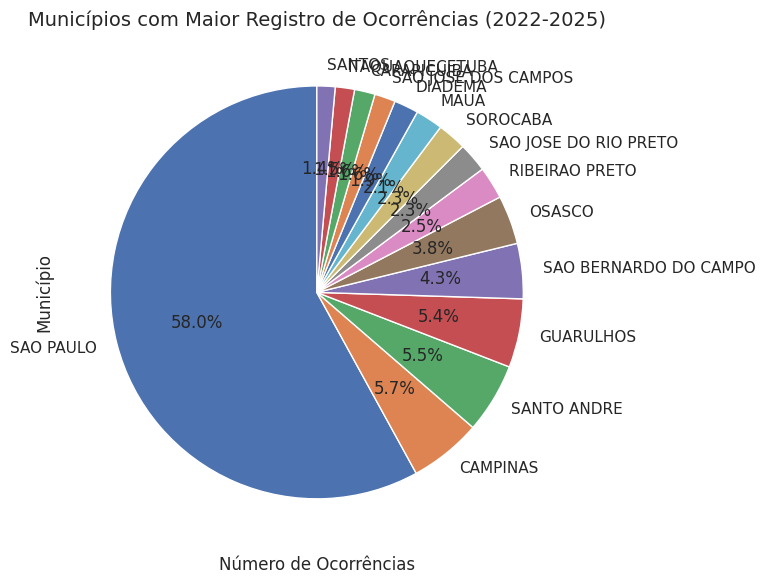

/tmp/ipykernel_4372/605882270.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_naturezas.values, y=top_naturezas.index, palette="magma")


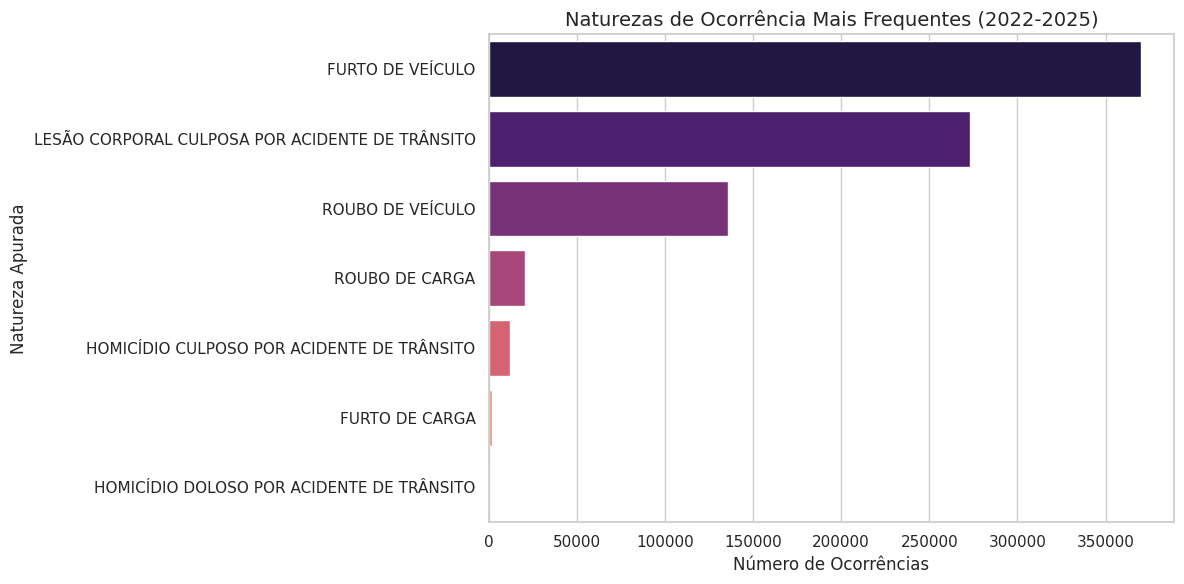


Processando coordenadas para o mapa...


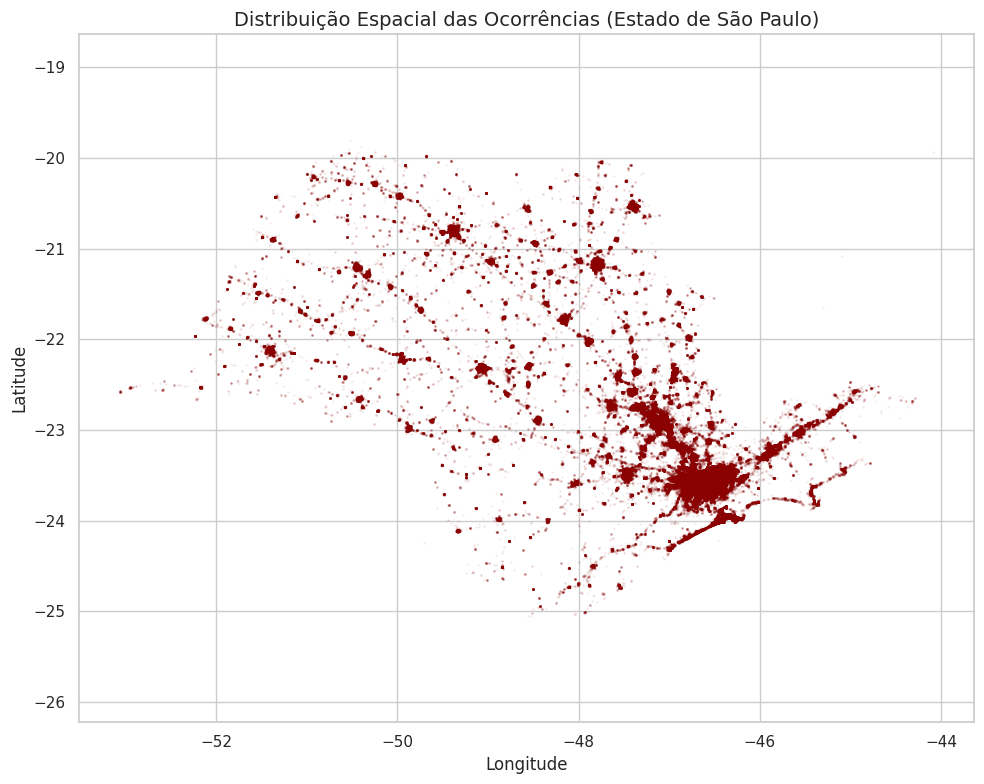

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Unificando os datasets
# Assumindo que o dicionário 'datasets' foi criado no script anterior
#df_completo = pd.concat(datasets.values(), ignore_index=True)

# Configuração de estilo visual para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ==========================================
# Gráfico 1: Frequência por Município (Top 15)
# ==========================================
plt.figure()
top_municipios = df_completo['NOME_MUNICIPIO'].value_counts().head(15)

plt.pie(top_municipios.values, labels=top_municipios.index, autopct='%1.1f%%', startangle=90)
plt.title('Municípios com Maior Registro de Ocorrências (2022-2025)', fontsize=14)
plt.xlabel('Número de Ocorrências')
plt.ylabel('Município')
plt.tight_layout()
plt.show()

# ==========================================
# Gráfico 2: Frequência por Natureza Apurada
# ==========================================
plt.figure()
top_naturezas = df_completo['NATUREZA_APURADA'].value_counts()

sns.barplot(x=top_naturezas.values, y=top_naturezas.index, palette="magma")
plt.title('Naturezas de Ocorrência Mais Frequentes (2022-2025)', fontsize=14)
plt.xlabel('Número de Ocorrências')
plt.ylabel('Natureza Apurada')
plt.tight_layout()
plt.show()

# ==========================================
# Gráfico 3: Mapa Simplificado (Scatter Plot)
# ==========================================
print("\nProcessando coordenadas para o mapa...")

# Convertendo vírgula para ponto e forçando tipo numérico (valores inválidos viram NaN)
df_completo['LATITUDE'] = pd.to_numeric(df_completo['LATITUDE'].astype(str).str.replace(',', '.'), errors='coerce')
df_completo['LONGITUDE'] = pd.to_numeric(df_completo['LONGITUDE'].astype(str).str.replace(',', '.'), errors='coerce')

# Removendo nulos nas coordenadas
df_mapa = df_completo.dropna(subset=['LATITUDE', 'LONGITUDE'])

# Filtrando bounding box aproximada do Estado de São Paulo para evitar outliers globais
# (Isso evita que uma coordenada digitada errada como (0,0) estrague a escala do gráfico)
filtro_sp = (
    (df_mapa['LATITUDE'] > -26.0) & (df_mapa['LATITUDE'] < -19.0) &
    (df_mapa['LONGITUDE'] > -54.0) & (df_mapa['LONGITUDE'] < -44.0)
)
df_mapa = df_mapa[filtro_sp]

plt.figure(figsize=(10, 8))
# X é Longitude e Y é Latitude. Usamos alpha baixo (0.05) e tamanho de ponto pequeno (s=1) para ver a densidade
plt.scatter(df_mapa['LONGITUDE'], df_mapa['LATITUDE'], alpha=0.05, s=1, c='darkred')
plt.title('Distribuição Espacial das Ocorrências (Estado de São Paulo)', fontsize=14)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.axis('equal') # Mantém a proporção real do mapa
plt.tight_layout()
plt.show()

Esta célula prepara dados para um mapa de calor:
*   Converte colunas de data e hora.
*   Extrai dia da semana e hora do dia.
*   Agrega ocorrências por dia da semana e hora, criando uma matriz para o heatmap.
*   O heatmap identifica padrões de crimes ao longo da semana e do dia.

### Mapa de Calor: Concentração de Crimes por Dia e Hora

Este bloco de código gera um gráfico de linha que mostra a evolução temporal do número de ocorrências para as 7 naturezas apuradas mais frequentes. Ele agrupa os dados por ano e natureza, permitindo visualizar tendências ao longo do tempo.

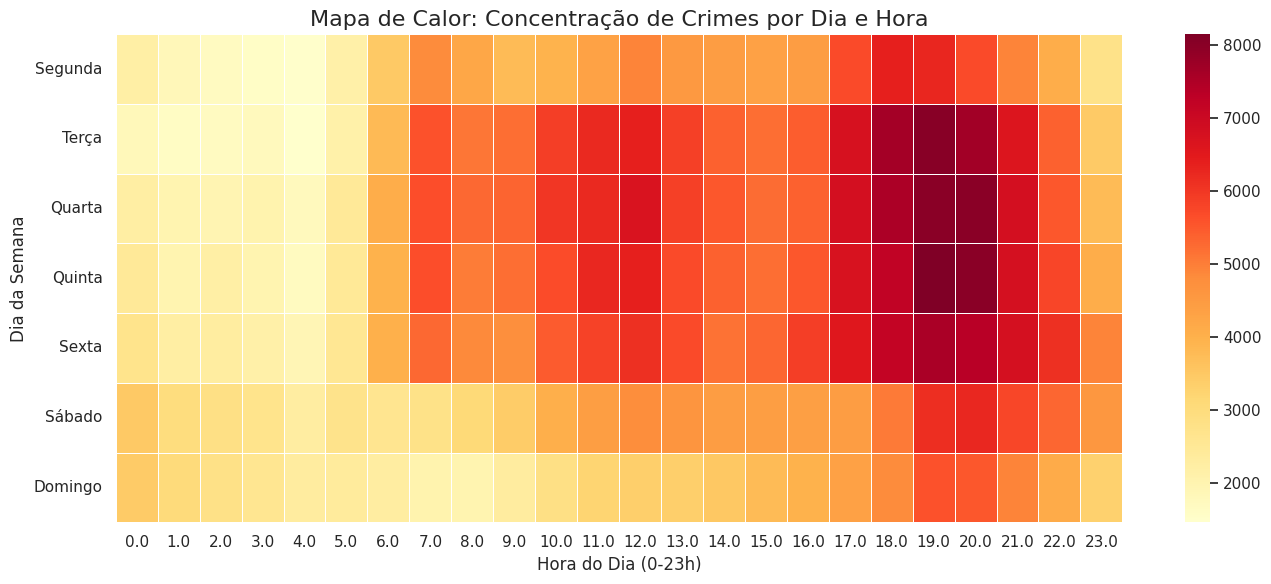

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Tratamento da Data
# Coerce transforma erros (como datas 31/02) em NaT (Not a Time)
df_completo['DATA'] = pd.to_datetime(df_completo['DATA_OCORRENCIA_BO'], errors='coerce')

# Extraindo dia da semana (0 = Segunda, 6 = Domingo)
df_completo['DIA_SEMANA'] = df_completo['DATA'].dt.dayofweek

# Mapeando para nomes em português para o gráfico
dias_map = {0: 'Segunda', 1: 'Terça', 2: 'Quarta', 3: 'Quinta', 4: 'Sexta', 5: 'Sábado', 6: 'Domingo'}
df_completo['NOME_DIA_SEMANA'] = df_completo['DIA_SEMANA'].map(dias_map)

# Tratamento da Hora
# Remove espaços, preenche nulos temporariamente e extrai apenas a hora (antes do ':')
df_completo['HORA_LIMPA'] = df_completo['HORA_OCORRENCIA_BO'].astype(str).str.strip().str.split(':').str[0]

# Converte para numérico, transformando sujeiras em NaN
df_completo['HORA_INT'] = pd.to_numeric(df_completo['HORA_LIMPA'], errors='coerce')

# Filtra horas válidas (0 a 23) E 'NOME_DIA_SEMANA' não nulo para garantir grupos válidos para o heatmap
df_heatmap = df_completo[
    (df_completo['HORA_INT'] >= 0) & (df_completo['HORA_INT'] <= 23) &
    (df_completo['NOME_DIA_SEMANA'].notna())
].copy()

# Criando a Matriz para o Heatmap
# Conta as ocorrências agrupando por Dia da Semana e Hora
matriz_crimes = df_heatmap.groupby(['NOME_DIA_SEMANA', 'HORA_INT']).size().unstack(fill_value=0)

# Ordenando os dias da semana logicamente (Segunda a Domingo)
ordem_dias = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
# Reindexando com fill_value=0 para manter a estrutura e preencher dias sem dados.
matriz_crimes = matriz_crimes.reindex(ordem_dias, fill_value=0)

# Plotando o Heatmap
plt.figure(figsize=(14, 6))
# Verifica se matriz_crimes não está vazia antes de tentar plotar
if not matriz_crimes.empty:
    sns.heatmap(matriz_crimes, cmap='YlOrRd', linewidths=.5, annot=False)
    plt.title('Mapa de Calor: Concentração de Crimes por Dia e Hora', fontsize=16)
    plt.xlabel('Hora do Dia (0-23h)', fontsize=12)
    plt.ylabel('Dia da Semana', fontsize=12)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Não há dados válidos para gerar o mapa de calor após o tratamento das datas e horas.")

Este bloco gera um gráfico de linha para a evolução temporal das 7 naturezas de ocorrência mais frequentes.
*   Agrupa dados por ano e natureza.
*   Visualiza tendências ao longo do tempo.
*   Utiliza 7 cores distintas e linhas mais grossas.

Gerando gráfico de linha para evolução temporal dos crimes por natureza apurada...


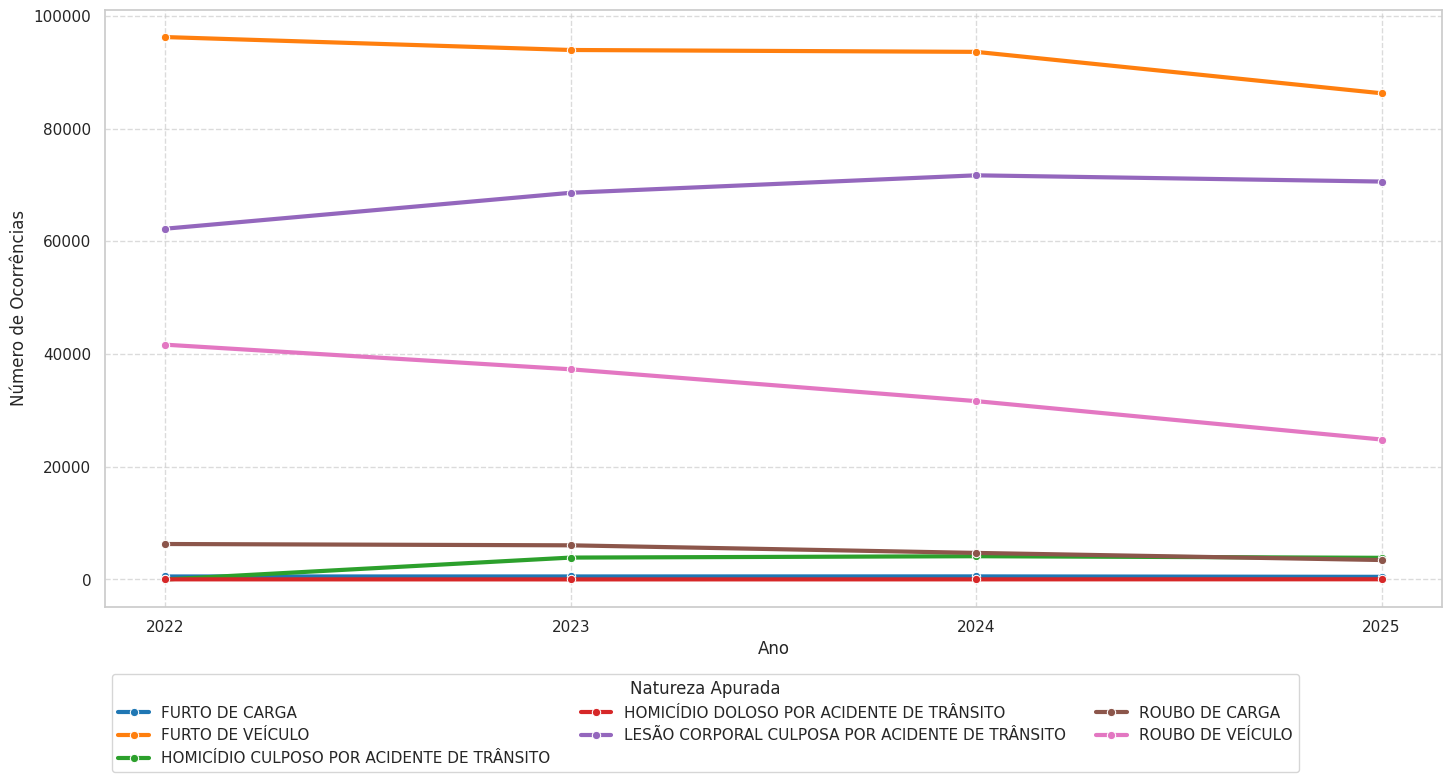

In [ ]:
print('Gerando gráfico de linha para evolução temporal dos crimes por natureza apurada...')

# 1. Obter as 7 naturezas apuradas mais frequentes
top_7_naturezas = df_completo['NATUREZA_APURADA'].value_counts().head(7).index.tolist()

# 2. Filtrar o DataFrame para incluir apenas essas 7 naturezas
df_top_naturezas = df_completo[df_completo['NATUREZA_APURADA'].isin(top_7_naturezas)].copy()


# 4. Agrupar por ano e natureza apurada e contar as ocorrências
evolucao_anual_natureza = df_top_naturezas.groupby(['ANO_BO', 'NATUREZA_APURADA']).size().unstack(fill_value=0)

# Se a coluna 'ANO' não for o índice, redefinir para garantir
evolucao_anual_natureza = evolucao_anual_natureza.reset_index()

# 5. Plotar o gráfico de linha
plt.figure(figsize=(15, 8))
# Definindo uma paleta de 7 cores distintas
custom_palette = sns.color_palette('tab10', n_colors=7)

sns.lineplot(
    data=evolucao_anual_natureza.melt(id_vars='ANO_BO', var_name='Natureza Apurada', value_name='Número de Ocorrências'),
    x='ANO_BO',
    y='Número de Ocorrências',
    hue='Natureza Apurada',
    marker='o', # Adiciona marcadores para cada ponto de dados
    palette=custom_palette, # Usando a paleta de cores personalizada
    linewidth=3 # Linhas mais grossas
)

#plt.title('Evolução Anual do Número de Ocorrências por Natureza Apurada (2023 - 2025)', fontsize=16)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Número de Ocorrências', fontsize=12)
plt.xticks(sorted(df_top_naturezas['ANO_BO'].dropna().unique())) # Garante que todos os anos sejam exibidos no eixo x
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Natureza Apurada', bbox_to_anchor=(0, -0.1), ncols=3, loc='upper left') # Coloca a legenda fora do gráfico
plt.tight_layout()
plt.show()

Esta célula analisa dados da capital (São Paulo):
*   Filtra ocorrências para 'SAO PAULO'.
*   **Gráfico de Barras (Top Bairros):** Mostra os 20 bairros com maior incidência de crimes.
*   **Mapa de Dispersão (Capital):** Categoriza crimes em macro-categorias (Roubo, Furto, Trânsito, Estelionato, Outros) e os plota, identificando pontos quentes por tipo de crime.

Total de registros na capital: 281517

Limpando nomes de bairros e gerando gráfico...


/tmp/ipykernel_5614/1641529687.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_bairros.values, y=top_bairros.index, palette="mako")


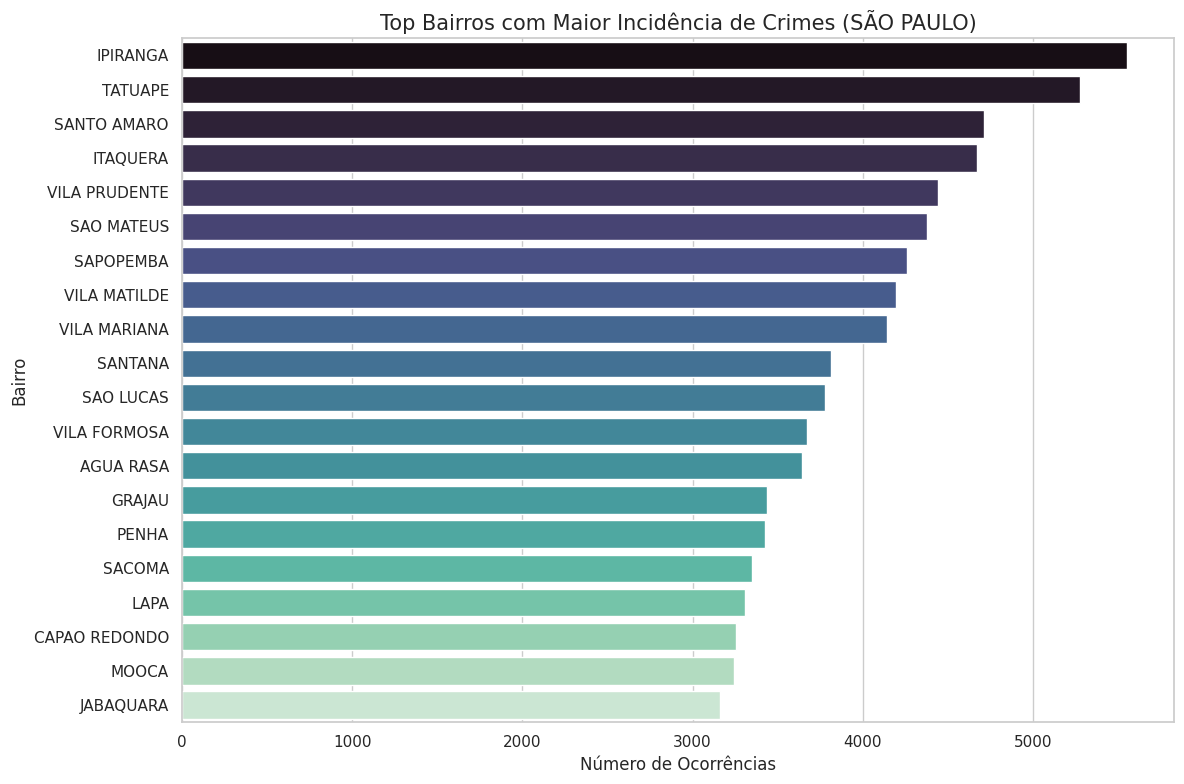


Aplicando recortes espaciais e gerando o mapa da cidade...
Categorizando os crimes...


/tmp/ipykernel_5614/1641529687.py:89: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(
/tmp/ipykernel_5614/1641529687.py:107: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  legenda = plt.legend(title='Categoria do Crime', title_fontsize='13', fontsize='11', loc='lower right', markerscale=5)


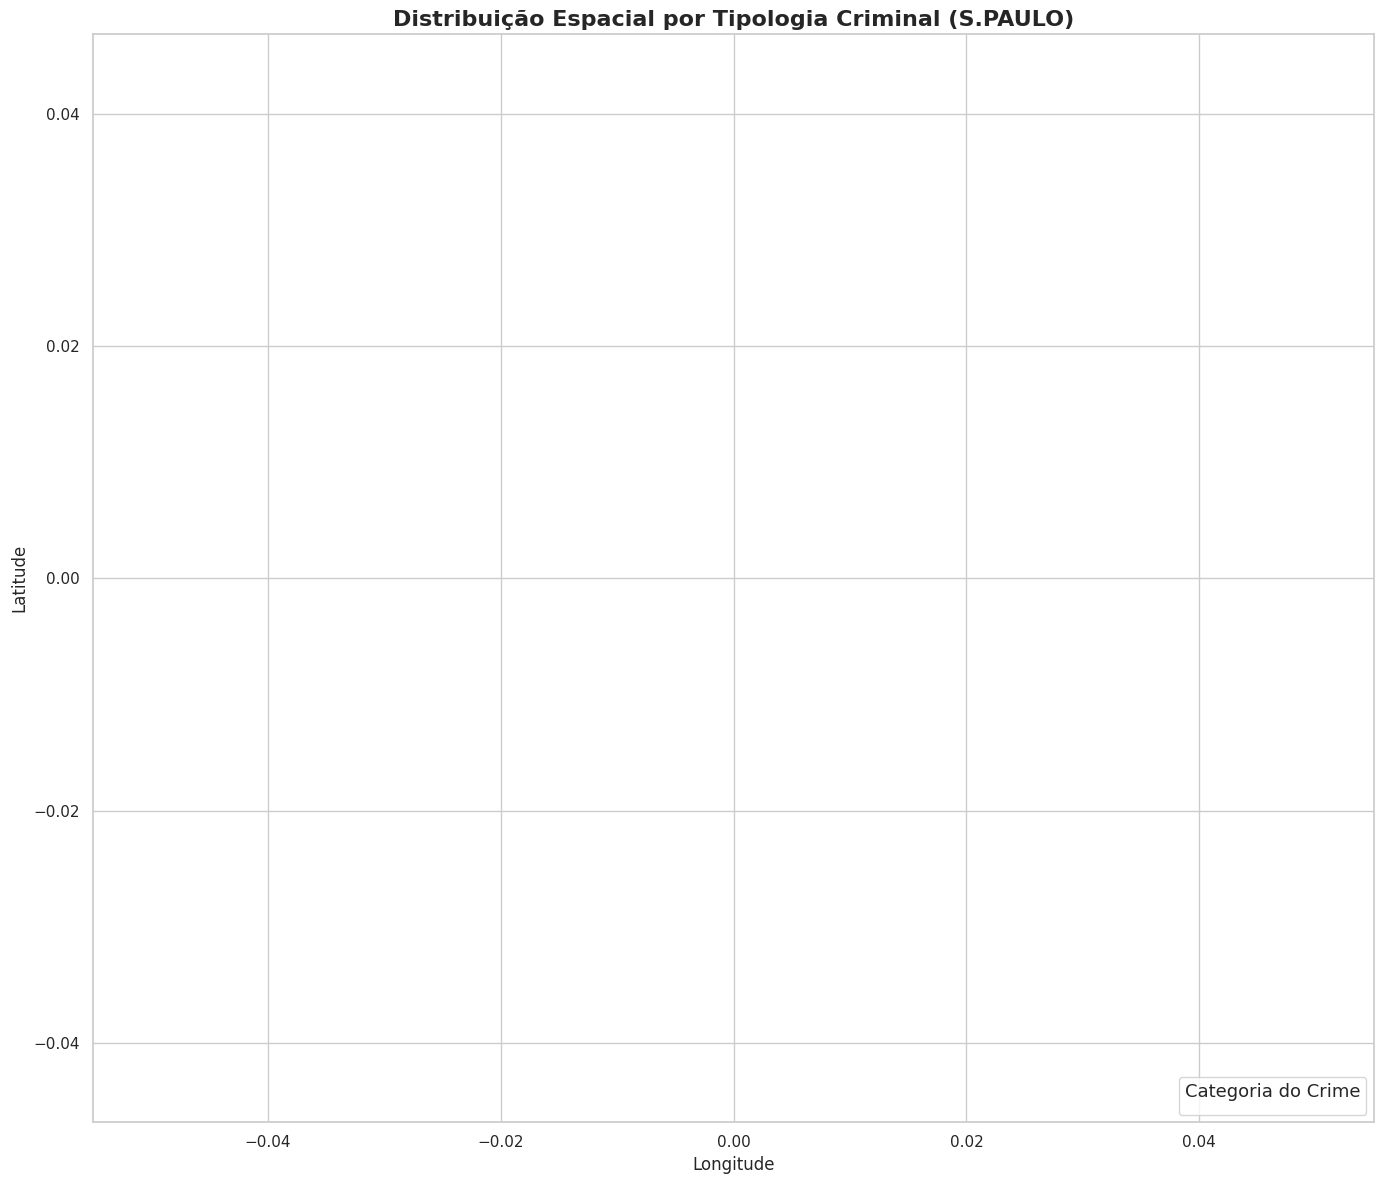

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Filtrando apenas as ocorrências da capital
df_capital = df_completo[df_completo['NOME_MUNICIPIO'] == 'SAO PAULO'].copy()

print(f"Total de registros na capital: {df_capital.shape[0]}")

# ==========================================
# Gráfico 1: Frequência por Bairro (Top 20)
# ==========================================
print("\nLimpando nomes de bairros e gerando gráfico...")

# Limpeza: converte para string, maiúsculo e remove espaços nas pontas
df_capital['BAIRRO_LIMPO'] = df_capital['BAIRRO'].astype(str).str.upper().str.strip()

# Pegando os 20 bairros com mais registros
top_bairros = df_capital['BAIRRO_LIMPO'].value_counts().head(20)

# Removendo a categoria "NAN" caso as linhas sem bairro fiquem no top 20
if 'NAN' in top_bairros.index:
    top_bairros = top_bairros.drop('NAN')

plt.figure(figsize=(12, 8))
sns.barplot(x=top_bairros.values, y=top_bairros.index, palette="mako")
plt.title('Top Bairros com Maior Incidência de Crimes (SÃO PAULO)', fontsize=15)
plt.xlabel('Número de Ocorrências', fontsize=12)
plt.ylabel('Bairro', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# Gráfico 2: Mapa de Dispersão (Capital)
# ==========================================

print("\nAplicando recortes espaciais e gerando o mapa da cidade...")

# 1. Função para criar Macro-Categorias de Crimes
def agrupar_natureza(natureza):
    nat = str(natureza).upper()
    if 'TRÂNSITO' in nat or 'CULPOSO NA DIREÇÃO' in nat or 'EMBRIAGUEZ' in nat:
        return 'Crimes de Trânsito'
    elif 'ROUBO' in nat:
        return 'Roubo'
    elif 'FURTO' in nat:
        return 'Furto'
    elif 'ESTELIONATO' in nat: # Explodiu em volume nos últimos anos em SP
        return 'Estelionato'
    else:
        return 'Outros'

print("Categorizando os crimes...")

# Filter df_completo for S.PAULO and valid coordinates to create df_mapa_sp for the scatter plot.
# Re-using logic from H5ppxsY-AdLT to create df_mapa_sp correctly, if it wasn't already available or was empty.
# Convertendo vírgula para ponto e forçando tipo numérico (valores inválidos viram NaN) on df_completo for safety
df_completo['LATITUDE'] = pd.to_numeric(df_completo['LATITUDE'].astype(str).str.replace(',', '.'), errors='coerce')
df_completo['LONGITUDE'] = pd.to_numeric(df_completo['LONGITUDE'].astype(str).str.replace(',', '.'), errors='coerce')

# Removendo nulos nas coordenadas e filtrando para S.PAULO
df_mapa_sp = df_completo[df_completo['NOME_MUNICIPIO'] == 'S.PAULO'].dropna(subset=['LATITUDE', 'LONGITUDE']).copy()

# Filtrando bounding box aproximada do Estado de São Paulo para evitar outliers globais
filtro_sp_cidade = (
    (df_mapa_sp['LATITUDE'] > -26.0) & (df_mapa_sp['LATITUDE'] < -19.0) &
    (df_mapa_sp['LONGITUDE'] > -54.0) & (df_mapa_sp['LONGITUDE'] < -44.0)
)
df_mapa_sp = df_mapa_sp[filtro_sp_cidade]

# Now apply the categorization function
df_mapa_sp['MACRO_CATEGORIA'] = df_mapa_sp['NATUREZA_APURADA'].apply(agrupar_natureza)

# 2. Configurando o Mapa Colorido
plt.figure(figsize=(14, 12))

# Definindo uma paleta de cores contrastante e intuitiva
cores_customizadas = {
    'Roubo': '#e41a1c',               # Vermelho
    'Furto': '#ff7f00',               # Laranja
    'Crimes de Trânsito': '#377eb8',  # Azul
    'Estelionato': '#984ea3',         # Roxo
    'Outros': '#999999'               # Cinza (base)
}

# Plotando com Seaborn usando hue
# Dica de otimização: se o dataset tiver milhões de linhas, o Seaborn pode demorar.
# Usamos alpha baixo para lidar com a sobreposição de pontos.
sns.scatterplot(
    data=df_mapa_sp,
    x='LONGITUDE',
    y='LATITUDE',
    hue='MACRO_CATEGORIA',
    palette=cores_customizadas,
    s=5,           # Tamanho do ponto (ajuste conforme a quantidade de dados)
    alpha=0.3,     # Transparência
    edgecolor=None # Remove a borda dos pontos para não poluir
)

plt.title('Distribuição Espacial por Tipologia Criminal (S.PAULO)', fontsize=16, fontweight='bold')
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.axis('equal') # Mantém a proporção real de SP

# Ajustando a legenda para que os pontos fiquem maiores nela do que no mapa
# CORRECTED: Pass markerscale directly to plt.legend()
legenda = plt.legend(title='Categoria do Crime', title_fontsize='13', fontsize='11', loc='lower right', markerscale=5)

# Keep set_alpha as it's common to both Line2D and PathCollection objects
for handle in legenda.legend_handles:
    handle.set_alpha(1)

plt.tight_layout()
plt.show()

Esta célula calcula:
*   Quantidade total de ocorrências em São Paulo (capital).
*   Percentual de ocorrências da capital em relação ao total do estado.

In [ ]:
total_ocorrencias = len(df_completo)
ocorrencias_sp = len(df_capital)

percentual_sp = (ocorrencias_sp / total_ocorrencias) * 100

print(f"Quantidade de ocorrências em São Paulo: {ocorrencias_sp}")
print(f"Porcentagem de ocorrências em São Paulo sobre o total: {percentual_sp:.2f}%")

Quantidade de ocorrências em São Paulo: 281517
Porcentagem de ocorrências em São Paulo sobre o total: 34.60%


Este bloco cria uma tabela detalhada de ocorrências por mês e ano:
*   Extrai mês e ano das datas de ocorrência.
*   Agrupa os dados.
*   Adiciona linhas de 'Total' e 'Média' para análise da distribuição temporal.

In [ ]:
import pandas as pd

# Certifica que a coluna 'DATA' é do tipo datetime, caso não tenha sido processada ainda
# A linha acima está comentada porque a coluna 'DATA' já foi tratada na célula WlIJaaJaDxBg.
df_completo['DATA'] = pd.to_datetime(df_completo['DATA_OCORRENCIA_BO'], format='%Y-%m-%d', errors='coerce')

# Filtra linhas onde a DATA é nula
df_filtered = df_completo.dropna(subset=['DATA']).copy()

# Extrai o mês e o ano
df_filtered['MES'] = df_filtered['DATA'].dt.month
df_filtered['ANO'] = df_filtered['DATA'].dt.year

# Mapeia números de mês para nomes de mês em português
meses_map = {
    1: 'Janeiro', 2: 'Fevereiro', 3: 'Março', 4: 'Abril',
    5: 'Maio', 6: 'Junho', 7: 'Julho', 8: 'Agosto',
    9: 'Setembro', 10: 'Outubro', 11: 'Novembro', 12: 'Dezembro'
}
df_filtered['NOME_MES'] = df_filtered['MES'].map(meses_map)

# Conta as ocorrências por mês e ano
tabela_ocorrencias = df_filtered.groupby(['NOME_MES', 'ANO']).size().unstack(fill_value=0)

# Garante a ordem dos meses
ordem_meses = [
    'Janeiro', 'Fevereiro', 'Março', 'Abril',
    'Maio', 'Junho', 'Julho', 'Agosto',
    'Setembro', 'Outubro', 'Novembro', 'Dezembro'
]
tabela_ocorrencias = tabela_ocorrencias.reindex(ordem_meses, fill_value=0)

# Adiciona a linha de Total
tabela_ocorrencias.loc['Total'] = tabela_ocorrencias.sum()

# Adiciona a linha de Média (calcula a média dos meses, ignorando o Total)
tabela_ocorrencias.loc['Média'] = tabela_ocorrencias.iloc[:-1].mean()

# Formata a tabela para melhor visualização (arredonda a média para 2 casas decimais)
tabela_formatada = tabela_ocorrencias.copy()
tabela_formatada.loc['Média'] = tabela_formatada.loc['Média'].round(2)

print("Número de Ocorrências por Mês e Ano (com Total e Média):")
display(tabela_formatada)

Número de Ocorrências por Mês e Ano (com Total e Média):


ANO,2022,2023,2024,2025
NOME_MES,,,,
Janeiro,14292.00,16187.00,15496.00,15482.00
Fevereiro,14457.00,15873.00,15504.00,15730.00
Março,17865.00,18929.00,17175.00,16691.00
Abril,16186.00,16722.00,17285.00,16026.00
Maio,17081.00,18153.00,17527.00,17019.00
Junho,16840.00,17398.00,17490.00,15301.00
Julho,17680.00,17399.00,17084.00,15932.00
Agosto,18271.00,17772.00,17779.00,16191.00
Setembro,17635.00,17685.00,17331.00,16222.00


Esta célula carrega o arquivo CSV `populacao_municipiosSP.csv` para o DataFrame `df_populacao`.

In [ ]:
caminho_ibge_populacao = '/content/populacao_municipiosSP.csv'
df_populacao = pd.read_csv(caminho_ibge_populacao, sep=',', encoding='utf-8-sig', low_memory=False)


Esta célula pré-processa os dados de população:
*   Corrige nomes inconsistentes de municípios no `df_populacao` com um mapeamento.
*   Padroniza a coluna 'Local' (remove acentos, converte para maiúsculas).
*   Renomeia a coluna de população para `POPULACAO_2022` e converte para tipo numérico.

In [ ]:
# 1. Substituir inconsistências específicas usando o dicionário global mapeado anteriormente
df_populacao['Local'] = df_populacao['Local'].replace(MAPA_MUNICIPIOS_POPULACAO)

# 2. Padronizar a coluna 'Local' usando a função reutilizável
df_populacao['Local_PADRONIZADO'] = df_populacao['Local'].astype(str)
df_populacao = padronizar_nome_municipio(df_populacao, 'Local_PADRONIZADO')

# 3. Limpeza dos nomes de colunas lidos do CSV populacional
original_population_col = None
for col in df_populacao.columns:
    cleaned_col_name = col.replace('"', '').strip()
    if cleaned_col_name == 'População no último censo':
        original_population_col = col
        break

if original_population_col:
    df_populacao = df_populacao.rename(columns={original_population_col: 'POPULACAO_2022'})
    df_populacao['POPULACAO_2022'] = df_populacao['POPULACAO_2022'].astype(str).str.replace('"', '', regex=False)
    df_populacao['POPULACAO_2022'] = pd.to_numeric(df_populacao['POPULACAO_2022'], errors='coerce')
    print("df_populacao preparado com sucesso!")
else:
    print("Warning: Coluna de população não encontrada. Verifique o cabeçalho original do CSV.")

df_populacao preparado com sucesso!


Este bloco combina dados de ocorrências (`df_completo`) e população (`df_populacao`):
*   Calcula a taxa de ocorrências por mil habitantes.
*   Identifica e lista municípios sem dados populacionais correspondentes.
*   Remove municípios sem população para o cálculo da métrica final.

In [ ]:
# 3. Contar ocorrências por município no df_completo
ocorrencias_por_municipio = df_completo['NOME_MUNICIPIO'].value_counts().reset_index()
ocorrencias_por_municipio.columns = ['NOME_MUNICIPIO', 'TOTAL_OCORRENCIAS']

# 4. Unir com os dados de população
df_merged = pd.merge(
    ocorrencias_por_municipio,
    df_populacao[['Local_PADRONIZADO', 'POPULACAO_2022']],
    left_on='NOME_MUNICIPIO',
    right_on='Local_PADRONIZADO',
    how='left'
)

# Identificar municípios sem correspondência de população
municipios_sem_populacao = df_merged[df_merged['POPULACAO_2022'].isna()]

if not municipios_sem_populacao.empty:
    print(f"\n{len(municipios_sem_populacao)} municípios em df_completo sem correspondência de população no df_populacao:")
    display(municipios_sem_populacao[['NOME_MUNICIPIO']].head())
else:
    print("Todos os municípios em df_completo têm correspondência de população.")

# Remover linhas sem dados de população para o cálculo de ocorrências por habitante
df_final = df_merged.dropna(subset=['POPULACAO_2022']).copy()

# 5. Calcular ocorrências por mil habitantes
df_final['OCORRENCIAS_POR_MIL_HABITANTES'] = (df_final['TOTAL_OCORRENCIAS'] / df_final['POPULACAO_2022']) * 1000

print("\nCálculo de ocorrências por mil habitantes concluído.")


11 municípios em df_completo sem correspondência de população no df_populacao:


,NOME_MUNICIPIO
570,OUTRO PAIS
584,FLORINIA
646,SENADOR JOSE BENTO
647,IMBITUBA
648,EXTREMA



Cálculo de ocorrências por mil habitantes concluído.


Esta célula gera um gráfico de barras mostrando os Top 15 municípios com a maior taxa de ocorrências por mil habitantes:
*   Ordena o `df_final` pela taxa.
*   Visualiza a criminalidade normalizada por cidade.

/tmp/ipykernel_5614/1629073088.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


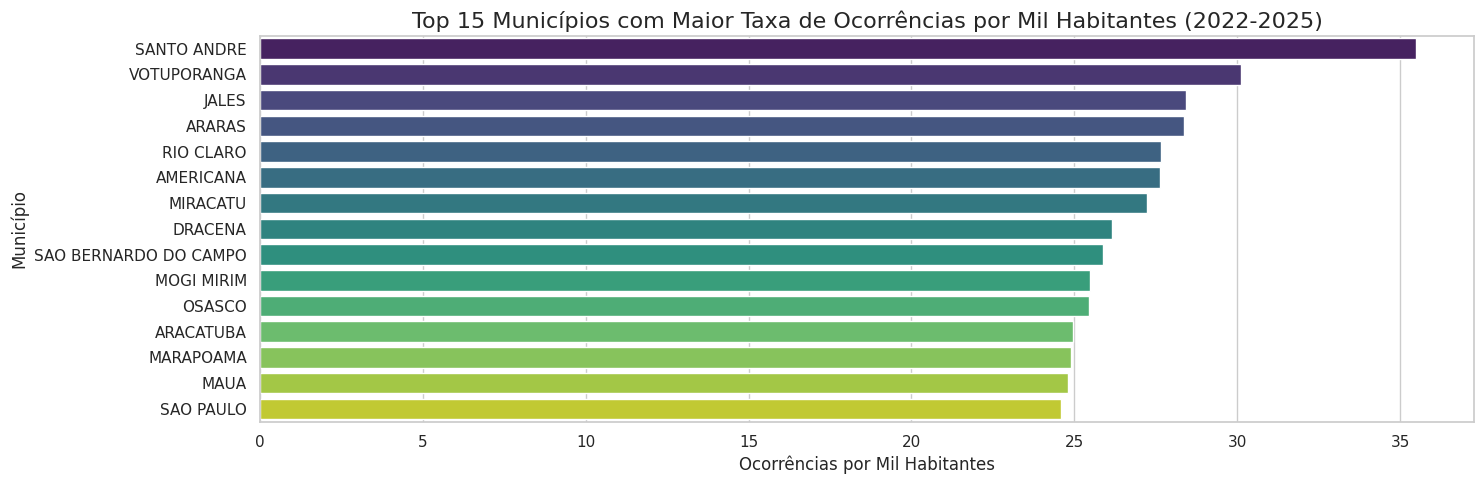

In [ ]:
# 6. Gerar o gráfico de barras
plt.figure(figsize=(15, 5))

# Ordenar para melhor visualização (Top 15)
df_plot = df_final.sort_values(by='OCORRENCIAS_POR_MIL_HABITANTES', ascending=False).head(15)

sns.barplot(
    x='OCORRENCIAS_POR_MIL_HABITANTES',
    y='NOME_MUNICIPIO',
    data=df_plot,
    palette='viridis'
)

plt.title('Top 15 Municípios com Maior Taxa de Ocorrências por Mil Habitantes (2022-2025)', fontsize=16)
plt.xlabel('Ocorrências por Mil Habitantes', fontsize=12)
plt.ylabel('Município', fontsize=12)
plt.tight_layout()
plt.show()